In [1]:
import pandas as pd
import os
import chardet
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

import bioread
from scipy.integrate import trapz
from scipy import stats
import warnings

import sys

sys.path.append(r'Z:\study\github\STATIS')
import PsychBehav as psychbehav


libpath = r'Z:\study\github\bioanalysis'
sys.path.append(libpath)
import gbatch_bioanalysis  as bioana

import importlib
importlib.reload(psychbehav) 

<module 'PsychBehav' from 'Z:\\study\\github\\STATIS\\PsychBehav.py'>

In [13]:
df['path[SubTrial]'].str.rsplit("\\",1,expand=True)[1].str.split('_',expand=True)[2]

C:\Users\XuanR\AppData\Local\Temp\ipykernel_37628\3357800536.py:1: FutureWarning: In a future version of pandas all arguments of StringMethods.rsplit except for the argument 'pat' will be keyword-only.
  df['path[SubTrial]'].str.rsplit("\\",1,expand=True)[1].str.split('_',expand=True)[2]


0          NaN
1      001.mp3
2      002.mp3
3      003.mp3
4      004.mp3
        ...   
311    153.mp3
312    154.mp3
313    155.mp3
314    156.mp3
315    157.mp3
Name: 2, Length: 316, dtype: object

C:\Users\XuanR\AppData\Local\Temp\ipykernel_37628\56504645.py:8: FutureWarning: In a future version of pandas all arguments of StringMethods.rsplit except for the argument 'pat' will be keyword-only.
  df['segID'] = df['path[SubTrial]'].str.rsplit("\\",1,expand=True)[1].str.split('_',expand=True)[2].str.replace('.mp3','').astype(float)
C:\Users\XuanR\AppData\Local\Temp\ipykernel_37628\56504645.py:8: FutureWarning: The default value of regex will change from True to False in a future version.
  df['segID'] = df['path[SubTrial]'].str.rsplit("\\",1,expand=True)[1].str.split('_',expand=True)[2].str.replace('.mp3','').astype(float)


<Axes: xlabel='V', ylabel='A'>

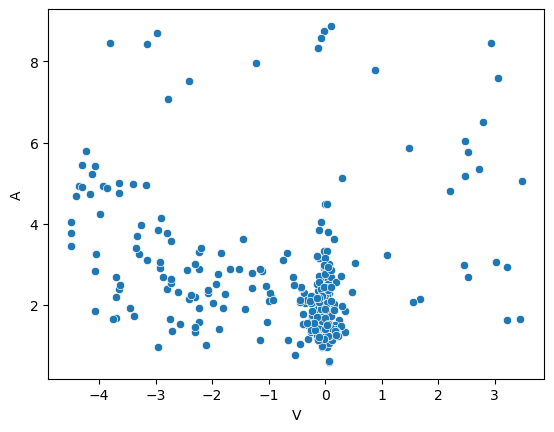

In [37]:
Dir_github = r'X:\PROJECTS\ABC@UofSC\3-Experiments\NSF_valence\github'
repo = 'ABC_valence'
Dir_working = os.path.join(Dir_github,'derivatives','behavioral','Exp_physio')
df_eprime = pd.read_csv(os.path.join(Dir_working,r'2.Outputs','1003-1004.txt'),sep='\t')

df = df_eprime.copy()
# df.columns = df_eprime.columns[53:]
df['segID'] = df['path[SubTrial]'].str.rsplit("\\",1,expand=True)[1].str.split('_',expand=True)[2].str.replace('.mp3','').astype(float)
df = df.loc[df['Running[SubTrial]']=='ListListenRateA']
df.loc[df['DXcoord']==0,'DXcoord'] = np.nan
df.loc[df['DYcoord']==0,'DYcoord'] = np.nan

df['V'] = psychbehav.rescale(df['DXcoord'],512-180,512+180,0,9).values
df['DYcoord'] *= -1
df['A'] = psychbehav.rescale(df['DYcoord'],-384-180,-384+180,0,9)


for label in ['V','A']:    
    df.loc[df[label]<0,label] = 0
    df.loc[df[label]>9,label] = 9


data_eprime = pd.DataFrame()
data_eprime[['subid','story','segID','V','A']] = df[['Subject','story','segID','V','A']]
data_eprime['V'] = data_eprime['V']-4.5
sns.scatterplot(data=data_eprime,x='V',y='A')

In [39]:
story = 'Elvis'
Dir_gpt = os.path.join(Dir_github,'derivatives','behavioral','ratings','gpt')
model = 'gpt-4o-2024-08-06'
dfs_rating_gpt = pd.read_csv(os.path.join(Dir_gpt,model,f'rating_gpt_{model}.csv'))
df_rating_gpt = dfs_rating_gpt.loc[dfs_rating_gpt['story']==story]
data_gpt = df_rating_gpt.groupby(['idx']).mean()

C:\Users\XuanR\AppData\Local\Temp\ipykernel_37628\83392224.py:6: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  data_gpt = df_rating_gpt.groupby(['idx']).mean()


In [55]:
data_eprime_wide

V             A       
subid         1003   1004   1003   1004
story segID                            
Elvis 1.0      NaN    NaN    NaN    NaN
      2.0      NaN -0.100    NaN  3.850
      3.0    2.725 -0.075  5.350  2.400
      4.0    0.300 -2.900  5.125  4.150
      5.0   -2.225 -0.375  3.300  2.300
...            ...    ...    ...    ...
      153.0  0.350  0.275  1.325  2.725
      154.0 -2.225 -0.450  1.575  2.125
      155.0 -2.300 -2.925  1.450  3.050
      156.0  0.100 -3.850  8.875  4.875
      157.0  0.050 -4.300  1.775  4.900

[157 rows x 4 columns]

[Text(0, 0.5, 'valence'), Text(0.5, 0, 'segment')]

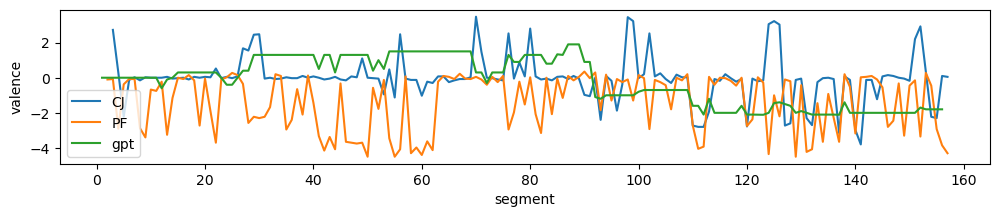

In [64]:
data_eprime_wide = data_eprime.pivot(index=['story','segID'],columns=['subid'])
fig,ax = plt.subplots(1,1,figsize=(12,2))
sns.lineplot(data_eprime_wide['V'].reset_index(),x='segID',y=1003,label='CJ')
sns.lineplot(data_eprime_wide['V'].reset_index(),x='segID',y=1004,label='PF')
sns.lineplot(data_gpt.reset_index(),x='idx',y='V',label='gpt')
ax.set(ylabel='valence',xlabel='segment')

In [120]:
theta = np.linspace(0, 2*np.pi, N, endpoint=False)
theta

array([0.        , 0.78539816, 1.57079633, 2.35619449, 3.14159265,
       3.92699082, 4.71238898, 5.49778714])

<BarContainer object of 1 artists>

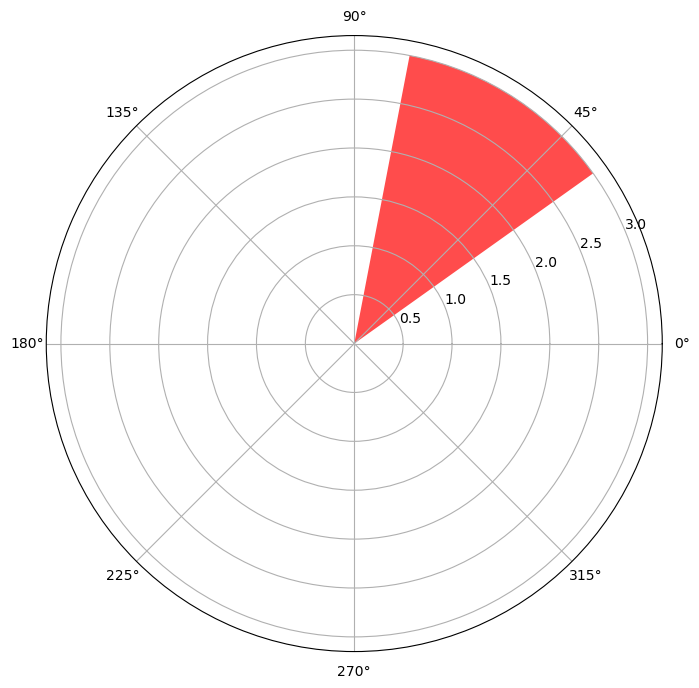

In [118]:
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(polar=True)
ax.bar(1, 3, width=width, color=color, alpha=0.7)

In [73]:
df_tmp = data_eprime_wide['V'].reset_index()
df_tmp['gpt'] = data_gpt['V']
df_tmp.corr()

C:\Users\XuanR\AppData\Local\Temp\ipykernel_37628\3317929824.py:3: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df_tmp.corr()


subid,segID,1003,1004,gpt
subid,,,,
segID,1.000000,-0.184570,-0.001144,-0.703939
1003,-0.184570,1.000000,0.050050,0.153027
1004,-0.001144,0.050050,1.000000,-0.019567
gpt,-0.703939,0.153027,-0.019567,1.000000


In [66]:
data_gpt

,idx_raw,V,A,flag,iteration
idx,,,,,
1,0.0,0.0,2.0,11.0,4.5
2,1.0,0.0,2.0,11.0,4.5
3,2.0,0.0,2.0,11.0,4.5
4,3.0,0.0,2.0,11.0,4.5
5,4.0,0.0,2.0,11.0,4.5
...,...,...,...,...,...
153,152.0,-1.8,5.2,11.0,4.5
154,153.0,-1.8,5.2,11.0,4.5
155,154.0,-1.8,5.2,11.0,4.5


# Correlation between human and gpt

Text(0, 2, 'r=0.1')

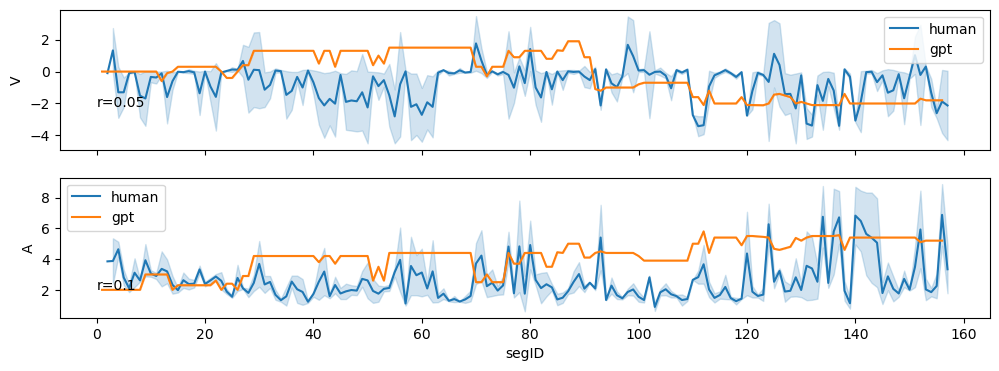

In [29]:
data_behav = pd.merge(left=data_eprime,left_on='segID',right=data_gpt[['V','A']],right_on='idx')
data_behav.columns = ['story','segID','V','A','V_gpt','A_gpt']
fig,axes = plt.subplots(ncols=1,nrows=2,figsize=(12,4),sharex=True)

ax=axes[0]
sns.lineplot(data_behav,x='segID',y='V',label='human',ax=ax)
sns.lineplot(data_behav,x='segID',y='V_gpt',label='gpt',ax=ax)
r = data_behav[['V','V_gpt']].corr().loc['V','V_gpt']
ax.text(x=0,y=-2.2,s=f"r={r.round(3)}")


ax=axes[1]
sns.lineplot(data_behav,x='segID',y='A',label='human',ax=ax)
sns.lineplot(data_behav,x='segID',y='A_gpt',label='gpt',ax=ax)
r = data_behav[['A','A_gpt']].corr().loc['A','A_gpt']
ax.text(x=0,y=2,s=f"r={r.round(3)}")

In [320]:
file = os.path.join(Dir_working,'2.Ouputs','pilot_narrative_preprocess.acq')
data = bioread.read_file(file)

In [322]:
design = dict()
design['channels'] = {'EDA':3,#'EDA_tonic':1,'EDA_phasic':20,
                      'EMGc':9,'EMGz':10,
                      'BPM':5,
                      'SKT':8,
                      }
design['sample_rate'] = data.samples_per_second
design['events'] = pd.DataFrame({'idx':range(4),
                                 'event':['stim_onset','stim_offset','rating_onset','trial_offset'],
                                 'label':['111','077','099','179']})

physio,events = bioana.read_data(data,design)
design['timing']= bioana.extract_trials(events,design)


In [396]:
def plot_heatmat(df_r,df_p):
    fig,axes = plt.subplots(ncols=2,nrows=1,figsize=(16,8))
    ax=axes[0]
    sns.heatmap(df_r,square=True,annot=True,annot_kws={"fontsize":8},
                cmap='coolwarm',
                cbar=False,
                # mask=df_p>.05,
                cbar_kws={'shrink':0.6},
                vmin=-1,vmax=1,
                ax=ax,
                # linewidths=0.1,linecolor='black'
                )

    ax=axes[1]
    sns.heatmap(df_r,square=True,annot=True,annot_kws={"fontsize":8},
                cmap='coolwarm',
                mask=df_p>.05,
                cbar=False,
                cbar_kws={'shrink':0.6},
                vmin=-1,vmax=1,
                ax=ax,
                # linewidths=0.1,linecolor='black'
                )


# Correlation between physio and behavioral

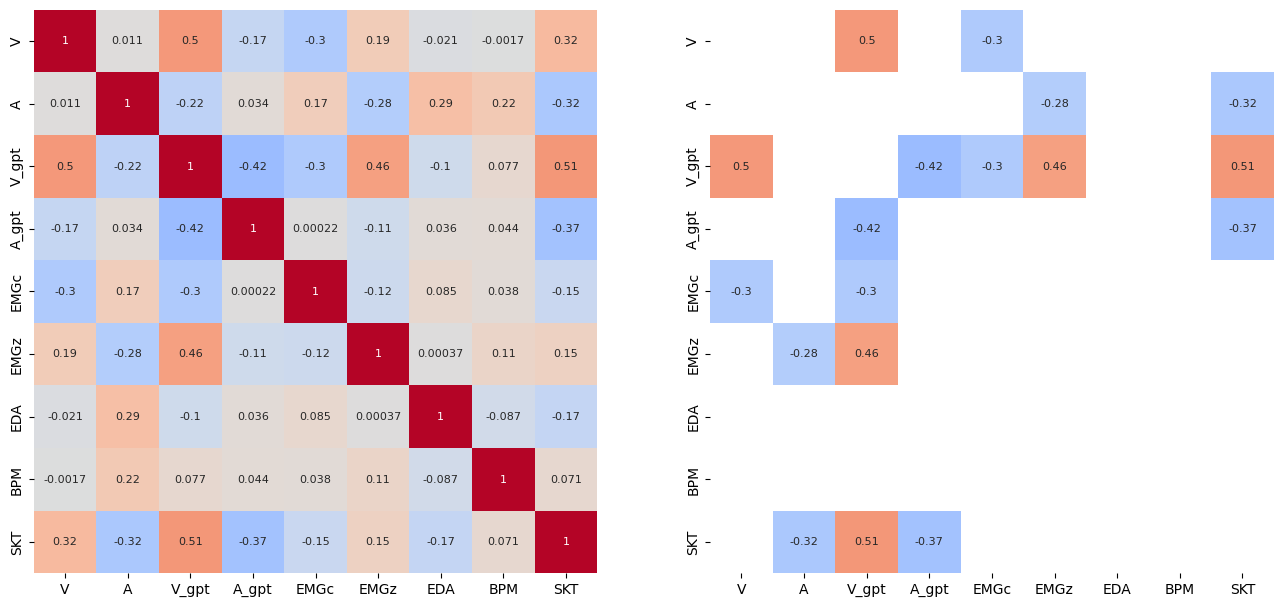

In [436]:
lag = 0
df_timing = pd.DataFrame({'onset':design['timing']['stim_onset']+lag,
                        'offset':design['timing']['stim_offset']+lag})
df_data = bioana.extract_physiodata(physio,df_timing,design,method='mean')
data_combine = pd.concat([data_behav,df_data],axis=1)[['V','A','V_gpt','A_gpt','EMGc','EMGz','EDA','BPM','SKT']]
df_r = data_combine.corr()
df_p = psychbehav.get_correlation(df_r)

plot_heatmat(df_r,df_p)

# Remove neutral

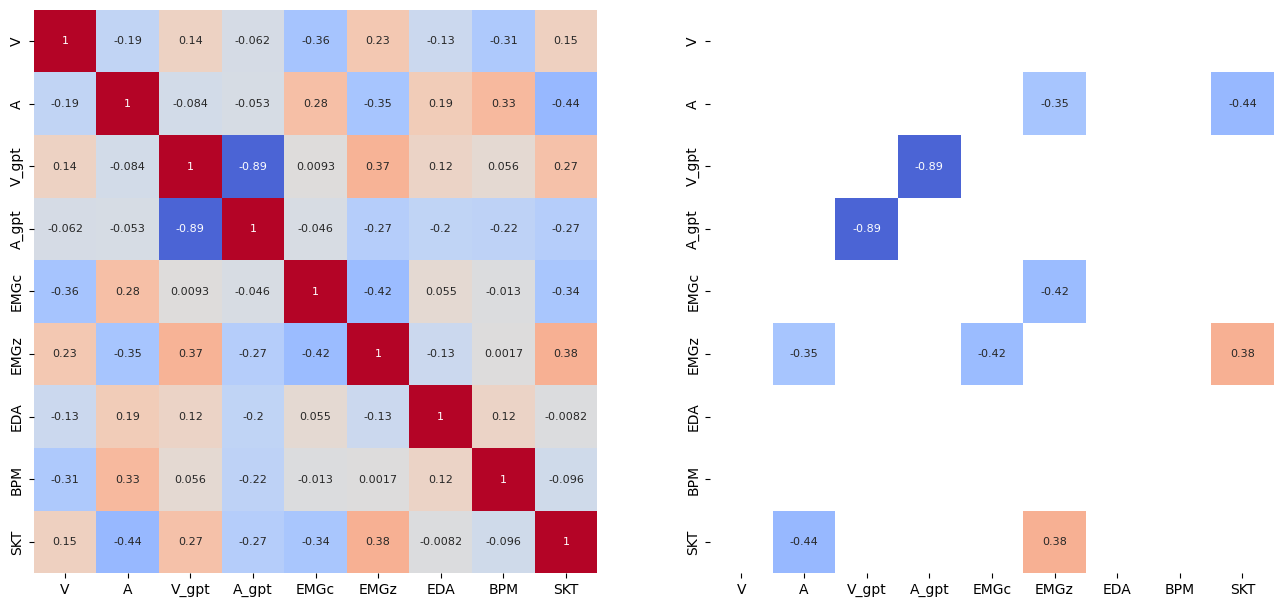

In [505]:
lag = 0
df_timing = pd.DataFrame({'onset':design['timing']['stim_onset']+lag,
                        'offset':design['timing']['stim_offset']+lag})
df_data = bioana.extract_physiodata(physio,df_timing,design,method='mean')
data_combine = pd.concat([data_behav,df_data],axis=1)[['V','A','V_gpt','A_gpt','EMGc','EMGz','EDA','BPM','SKT']]

data_combine = data_combine.loc[~(data_combine['V']>-0.5)&(data_combine['V']<0.5)]

df_r = data_combine.corr()
df_p = psychbehav.get_correlation(df_r)

plot_heatmat(df_r,df_p)

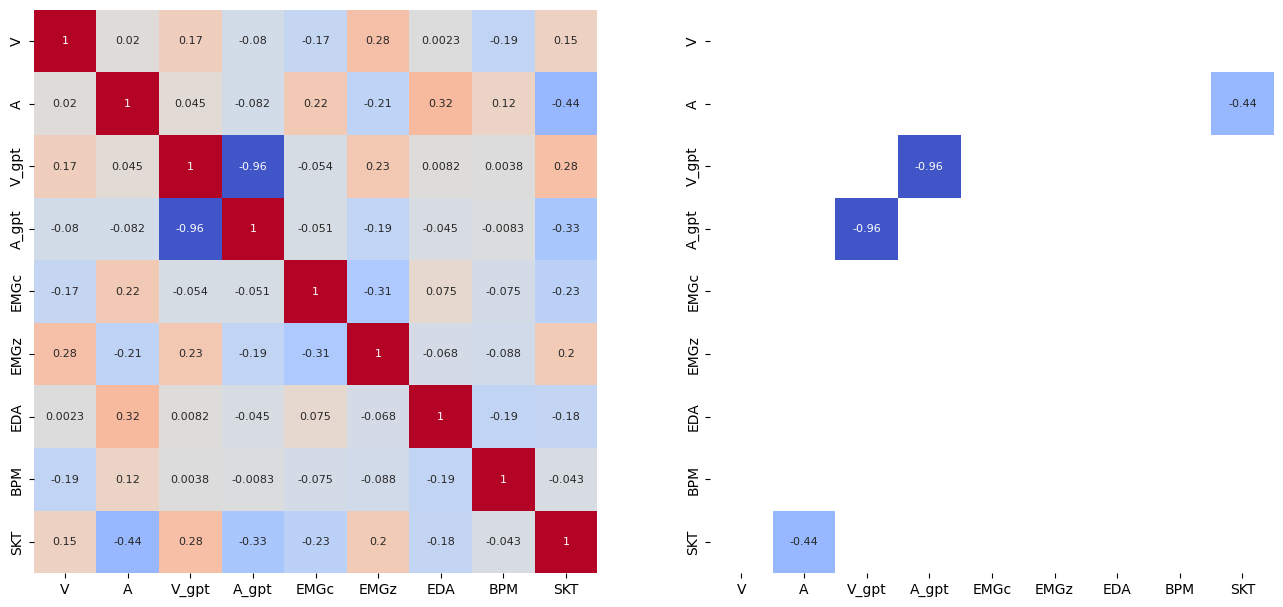

In [506]:
lag = 0
df_timing = pd.DataFrame({'onset':design['timing']['stim_onset']+lag,
                        'offset':design['timing']['stim_offset']+lag})
df_data = bioana.extract_physiodata(physio,df_timing,design,method='mean')
data_combine = pd.concat([data_behav,df_data],axis=1)[['V','A','V_gpt','A_gpt','EMGc','EMGz','EDA','BPM','SKT']]

data_combine = data_combine.loc[~(data_combine['V_gpt']>-0.5)&(data_combine['V_gpt']<0.5)]

df_r = data_combine.corr()
df_p = psychbehav.get_correlation(df_r)

plot_heatmat(df_r,df_p)

# Segment plot

In [ ]:
def plot_line_sec(df_plot,var,ax,color,alpha):
    

    df_plot['value'] = psychbehav.rescale(df_plot[var],df_plot[var].min(),df_plot[var].max(),-1,1)
    for i in range(len(df_plot)):
        # Plot the horizontal line for the current row
        ax.plot([df_plot.loc[i, 'onset'], df_plot.loc[i, 'offset']], 
                [df_plot.loc[i, 'value'], df_plot.loc[i,'value']],color=color,alpha = alpha)
        
        # Connect the offset of the current row to the onset of the next row
        if i < len(df_plot) - 1:  # Avoid index error for the last row
            ax.plot([df_plot.loc[i, 'offset'], df_plot.loc[i+1, 'onset']], 
                    [df_plot.loc[i, 'value'], df_plot.loc[i+1, 'value']],color=color,linestyle='-',alpha = alpha)

    ax.set(ylabel=var)

Dir_timestamps = os.path.join(Dir_github,'derivatives','behavioral','timestamps','timestamps_segment')
df_timestamps = pd.read_csv(os.path.join(Dir_timestamps,f"timestamps_Jacob_HowCouldYou.csv"))
df_timestamps['time'] = (df_timestamps['onset']+df_timestamps['offset'])/2


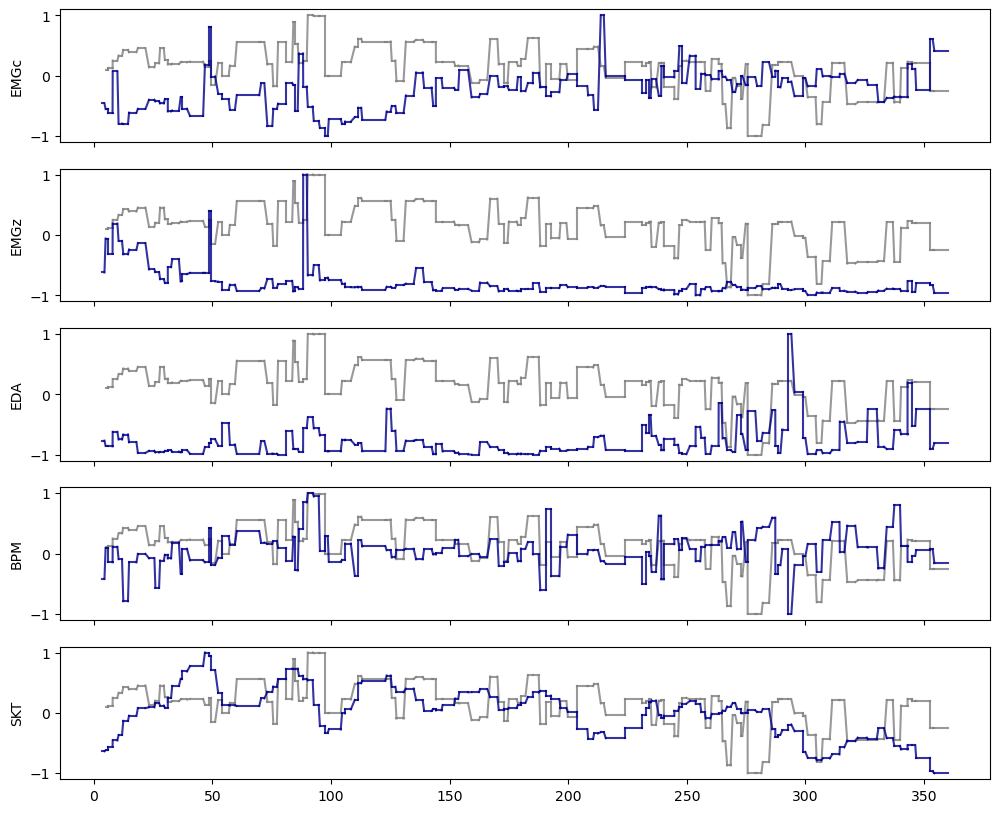

In [498]:

lag = 0
df_timing = pd.DataFrame({'onset':design['timing']['stim_onset']+lag,
                        'offset':design['timing']['stim_offset']+lag})
df_data = bioana.extract_physiodata(physio,df_timing,design,method='mean')
data_combine = pd.concat([data_behav,df_data],axis=1)[['V','A','V_gpt','A_gpt','EMGc','EMGz','EDA','BPM','SKT']]
data_combine['time'] = df_timestamps['time']
data_combine['onset'] = df_timestamps['onset']
data_combine['offset'] = df_timestamps['offset']
df_plot = data_combine.copy()

# fig,axes = plt.subplots(nrows=1,ncols=1,figsize=(12,2))
# plt.plot([1,2],2)

fig,axes = plt.subplots(nrows=5,ncols=1,figsize=(12,10),sharex=True)
for i,var in enumerate(['EMGc','EMGz','EDA','BPM','SKT']):
        
    plot_line_sec(df_plot,'V',axes[i],color='gray',alpha=0.8)
    # plot_line_sec(df_plot,'V_gpt',axes[i],color='darkgreen',alpha=0.8)
    plot_line_sec(df_plot,var,axes[i],color='darkblue',alpha=0.8)

plt.show()

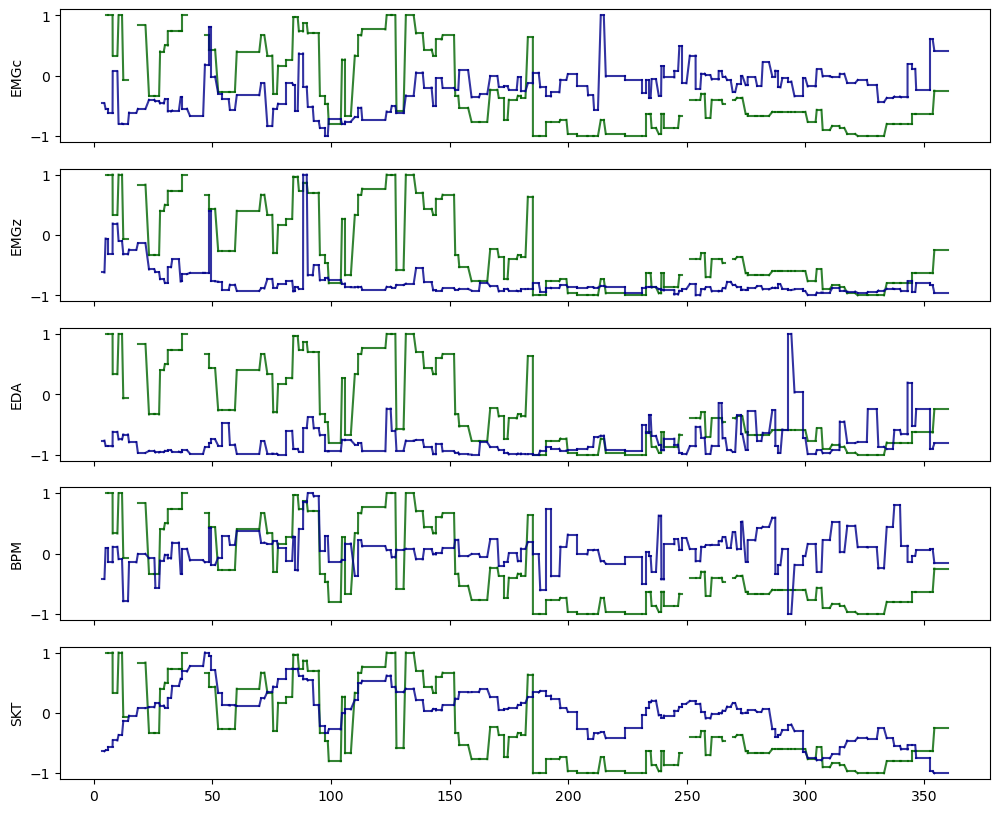

In [499]:
fig,axes = plt.subplots(nrows=5,ncols=1,figsize=(12,10),sharex=True)
for i,var in enumerate(['EMGc','EMGz','EDA','BPM','SKT']):
        
    # plot_line_sec(df_plot,'V',axes[i],color='gray',alpha=0.8)
    plot_line_sec(df_plot,'V_gpt',axes[i],color='darkgreen',alpha=0.8)
    plot_line_sec(df_plot,var,axes[i],color='darkblue',alpha=0.8)

plt.show()

# Time-lag correlation between physio and behavioral

In [507]:
dfs_r = []
dfs_p = []
for lag in np.arange(0, 751, 25):

    df_timing = pd.DataFrame({'onset':design['timing']['stim_onset']+lag,
                            'offset':design['timing']['stim_offset']+lag})
    df_data = bioana.extract_physiodata(physio,df_timing,design,method='mean')
    data_combine = pd.concat([data_behav,df_data],axis=1)[['V','A','V_gpt','A_gpt','EMGc','EMGz','EDA','BPM','SKT']]
    df_r = data_combine.corr()
    df_p = psychbehav.get_correlation(df_r)

    # plot_heatmat(df_r,df_p)

    df_r['lag'] = lag
    df_r.reset_index(inplace=True)
    df_p['lag'] = lag
    df_p.reset_index(inplace=True)
    dfs_r.append(df_r)
    dfs_p.append(df_p)
dfs_r = pd.concat(dfs_r)
dfs_p = pd.concat(dfs_p)


<Axes: xlabel='lag', ylabel='V_gpt'>

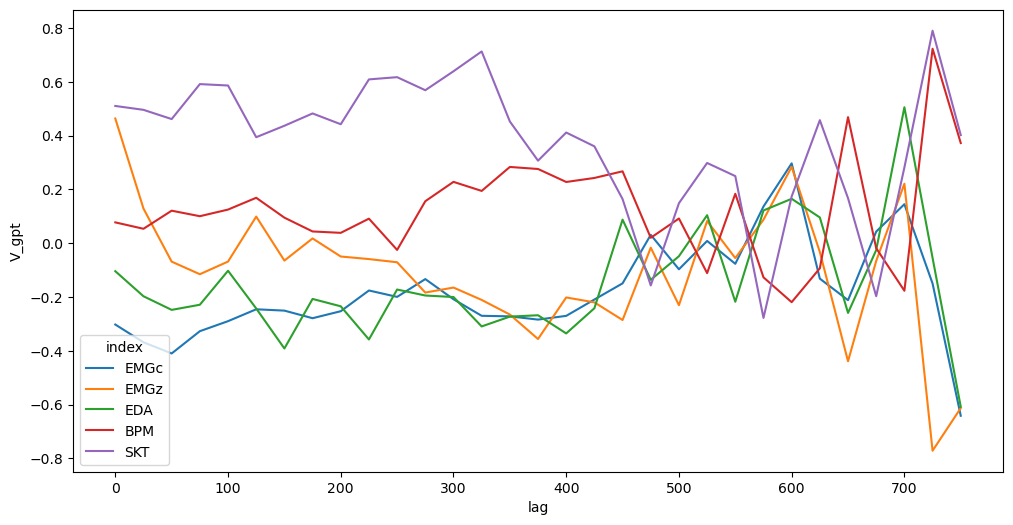

In [508]:
fig,axes = plt.subplots(ncols=1,nrows=1,figsize=(12,6))

df_plot = dfs_r.loc[dfs_r['index'].isin(list(design['channels'].keys()))]
ax=axes
sns.lineplot(df_plot,x='lag',y='V_gpt',hue='index')

<Axes: xlabel='lag', ylabel='V'>

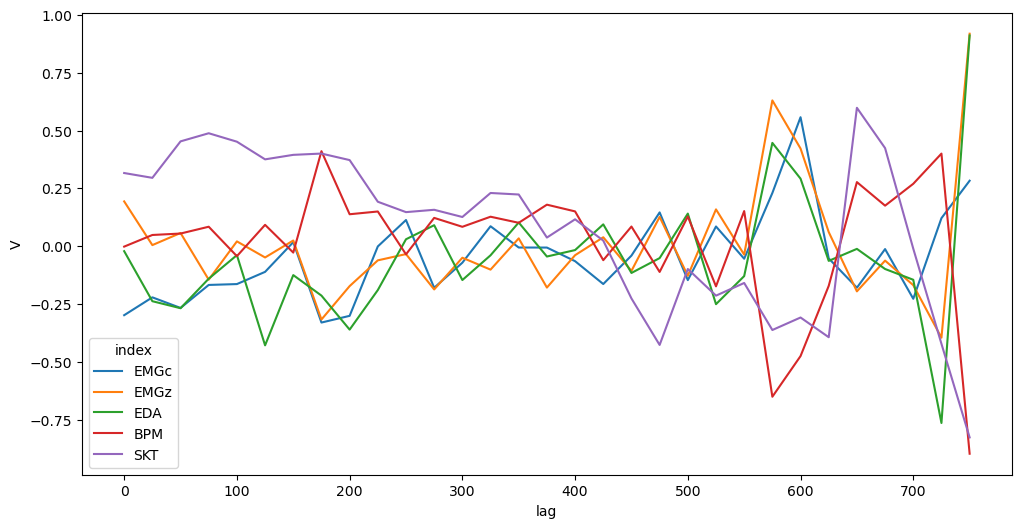

In [509]:
fig,axes = plt.subplots(ncols=1,nrows=1,figsize=(12,6))

df_plot = dfs_r.loc[dfs_r['index'].isin(list(design['channels'].keys()))]
ax=axes
sns.lineplot(df_plot,x='lag',y='V',hue='index')

In [ ]:

# Use another story, but same story two people


In [442]:
Dir_timestamps = os.path.join(Dir_github,'derivatives','behavioral','timestamps','timestamps_segment')
df_timestamps = pd.read_csv(os.path.join(Dir_timestamps,f"timestamps_Jacob_HowCouldYou.csv"))
df_timestamps['time'] = (df_timestamps['onset']+df_timestamps['offset'])/2

lag = 0
df_timing = pd.DataFrame({'onset':design['timing']['stim_onset']+lag,
                        'offset':design['timing']['stim_offset']+lag})
df_data = bioana.extract_physiodata(physio,df_timing,design,method='mean')
data_combine = pd.concat([data_behav,df_data],axis=1)[['V','A','V_gpt','A_gpt','EMGc','EMGz','EDA','BPM','SKT']]
data_combine['time'] = df_timestamps['time']
data_combine['onset'] = df_timestamps['onset']
data_combine['offset'] = df_timestamps['offset']
df_plot = data_combine.copy()

# fig,axes = plt.subplots(nrows=1,ncols=1,figsize=(12,2))
# plt.plot([1,2],2)

,segment,reason,story,idx,audio,segment_raw,onset,offset,words,time
0,"""When I was a puppy,",positioning element,HowCouldYou,0,Jacob_HowCouldYou,"""When I was a puppy,",3.48,4.500000,When|I|was|a|puppy,3.990000
1,I made you laugh.,>maximal segment,HowCouldYou,1,Jacob_HowCouldYou,I made you laugh.,4.97,5.970000,I|made|you|laugh,5.470000
2,You called me your child,-,HowCouldYou,2,Jacob_HowCouldYou,You called me your child,5.97,7.910000,You|called|me|your|child,6.940000
3,"and despite a number of chewed shoes,",conjunction / nonrestrictive clause,HowCouldYou,3,Jacob_HowCouldYou,"and despite a number of chewed shoes,",7.97,9.950000,and|despite|a|number|of|chewed|shoes,8.960000
4,I became your best friend.,conjunction cont.; >maximal segment,HowCouldYou,4,Jacob_HowCouldYou,I became your best friend.,10.44,11.899999,I|became|your|best|friend,11.169999
...,...,...,...,...,...,...,...,...,...,...
119,it was her job to make sure,complementizer (that…),HowCouldYou,119,Jacob_HowCouldYou,it was her job to make sure,343.02,344.790000,it|was|her|job|to|make|sure,343.905000
120,"I went to a better place,",complementizer (that…),HowCouldYou,120,Jacob_HowCouldYou,"I went to a better place,",344.79,346.280000,I|went|to|a|better|place,345.535000
121,where I wouldn't be ignored or abused or aband...,relative clause,HowCouldYou,121,Jacob_HowCouldYou,where I wouldn't be ignored or abused or aband...,346.66,352.300000,where|I|wouldn't|be|ignored|or|abused|or|aband...,349.480000
122,to fend for myself,infinitival phrase; >maximal segment,HowCouldYou,122,Jacob_HowCouldYou,to fend for myself,352.30,353.610000,to|fend|for|myself,352.955000


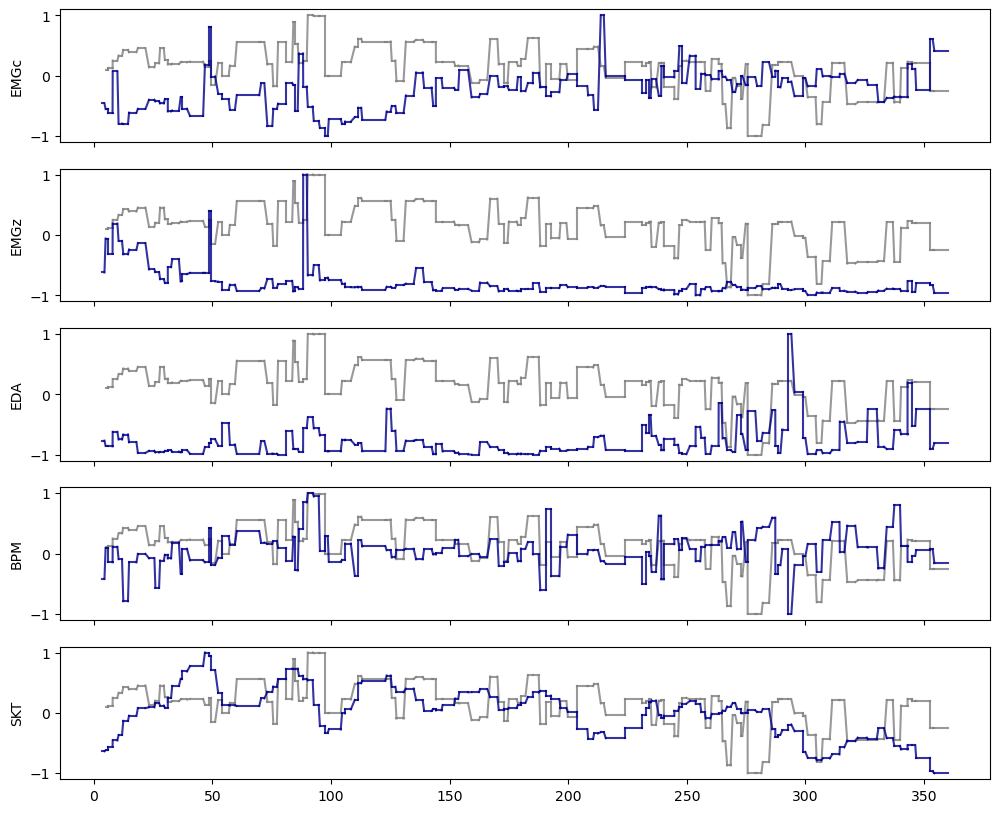

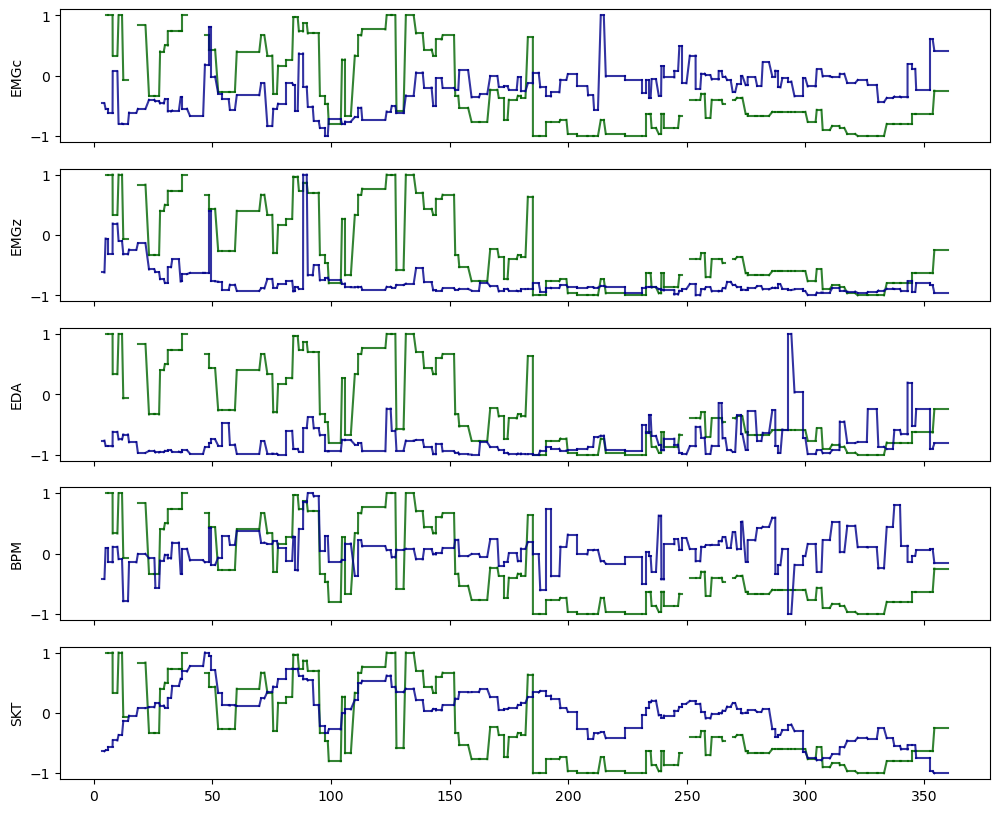